In [1]:
# import libraries
#!pip install numfracpy
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import tensorflow_probability as tfp
import time

# set double precision
#from numfracpy import Mittag_Leffler_two
from scipy.special import gamma
tf.keras.backend.set_floatx('float64')
tf_dtype = tf.float64

In [2]:
# @title
def tensor(x):
    return tf.convert_to_tensor(x, dtype=tf_dtype)

def visualize_solution(model, solution, x_data=None, u_data=None, with_param=None):
    # Solution visualization
    x_plot = tf.linspace(tensor([0.0]), tensor([1.0]), 300)
    if with_param is not None:
        p_plot = with_param * tf.ones(shape=(300, 1), dtype=tf_dtype)
        x_plot = tf.concat([x_plot, p_plot], axis=1)

    u_plot_ex = solution(x_plot)
    u_plot_nn = nn.predict(x_plot)[:, 0]

    plt.plot(x_plot[:, 0:1], u_plot_ex, c='b')
    plt.plot(x_plot[:, 0:1], u_plot_nn, '--', c='r')

    if x_data is not None:
        u_data_nn = nn.call(x_data)[:, 0]
        plt.scatter(x_data, u_data, c='b')
        plt.scatter(x_data, u_data_nn, c='r')

    if with_param is None:
        plt.title("Solution")
    else:
        plt.title("Solution with p = "+str(with_param))
    plt.xlabel("x")
    plt.legend(["Exact solution", "Network solution"], bbox_to_anchor=(1.05, 1.0), loc='upper left')
    plt.show()


def visualize_error(model, solution, with_param=None):
    # Error visualization
    x_plot = tf.linspace(tensor([0.0]), tensor([1.0]), 300)
    if with_param is not None:
        p_plot = with_param * tf.ones(shape=(300, 1), dtype=tf_dtype)
        x_plot = tf.concat([x_plot, p_plot], axis=1)

    u_plot_ex = solution(x_plot)
    u_plot_nn = nn.predict(x_plot)[:, 0]

    error = np.abs(np.squeeze(u_plot_ex)-u_plot_nn)
    plt.plot(x_plot[:, 0:1], error)

    if with_param is None:
        plt.title("Error (average error {:.2e})".format(np.mean(error)))
    else:
        plt.title("Error with p = "+str(with_param))

    plt.legend(["Absolute value of the error"], bbox_to_anchor=(1.05, 1.0), loc='upper left')
    plt.yscale("log")
    plt.xlabel("x")
    plt.ylabel("$|u-u^{NN}|$")
    plt.show()

def visualize_parametric_sol(model, solution):
    N = 100
    n_levels = 30

    x = np.linspace(0, 1, N)
    p = np.linspace(-1, 1, N)

    x, p = np.meshgrid(x, p)
    x_and_p = np.concatenate([x.reshape(N*N, 1), p.reshape(N*N, 1)], axis=1)
    x_and_p = tensor(x_and_p)

    # figure, axes = plt.subplots()
    fig = plt.figure()
    ax1 = fig.add_subplot(1,3,1)
    ax2 = fig.add_subplot(1,3,2)
    ax3 = fig.add_subplot(1,3,3)

    net_sol = model.call(x_and_p)[:, 0:1]
    plot_sol = net_sol.numpy().reshape(N, N)

    exact_sol = solution(x_and_p).numpy().reshape(N,N)

    im1 = ax1.contourf(x, p, plot_sol, levels=n_levels)
    ax1.contour(x, p, plot_sol, levels=n_levels, colors="k", linewidths=0.3)
    ax1.set_xlabel("x")
    ax1.set_ylabel("p")
    ax1.set_title("PINN")

    im2 = ax2.contourf(x, p, exact_sol, levels=n_levels)
    ax2.contour(x, p, exact_sol, levels=n_levels, colors="k", linewidths=0.3)
    ax2.set_xlabel("x")
    ax2.set_ylabel("p")
    ax2.set_title("Exact")

    im3 = ax3.contourf(x, p, np.abs(plot_sol - exact_sol), levels=n_levels)
    ax3.contour(x, p, np.abs(plot_sol - exact_sol), levels=n_levels, colors="k", linewidths=0.3)
    ax3.set_xlabel("x")
    ax3.set_ylabel("p")
    ax3.set_title("Error")

    fig.set_figwidth(15)
    fig.set_figheight(6)
    fig.colorbar(im1)
    fig.colorbar(im2)
    fig.colorbar(im3)
    fig.tight_layout(pad = 1)
    plt.show()



def visualize_1d_contour(model, solution):
    N = 100
    n_levels = 30

    x = np.linspace(0, 1, N)
    y = np.linspace(0, 1, N)

    x, y = np.meshgrid(x, y)
    xy = np.concatenate([x.reshape(N*N, 1), y.reshape(N*N, 1)], axis=1)
    xy = tensor(xy)

    # figure, axes = plt.subplots()
    fig = plt.figure()
    ax1 = fig.add_subplot(1,3,1)
    ax2 = fig.add_subplot(1,3,2)
    ax3 = fig.add_subplot(1,3,3)

    net_sol = model.predict(xy)[:, 0:1]
    plot_sol = net_sol.numpy().reshape(N, N)

    exact_sol = solution(xy).numpy().reshape(N,N)

    im1 = ax1.contourf(x, y, plot_sol, levels=n_levels)
    ax1.contour(x, y, plot_sol, levels=n_levels, colors="k", linewidths=0.3)
    ax1.set_xlabel("x")
    ax1.set_ylabel("t")
    ax1.set_title("PINN")

    im2 = ax2.contourf(x, y, exact_sol, levels=n_levels)
    ax2.contour(x, y, exact_sol, levels=n_levels, colors="k", linewidths=0.3)
    ax2.set_xlabel("x")
    ax2.set_ylabel("t")
    ax2.set_title("Exact")

    im3 = ax3.contourf(x, y, np.abs(plot_sol - exact_sol), levels=n_levels)
    ax3.contour(x, y, np.abs(plot_sol - exact_sol), levels=n_levels, colors="k", linewidths=0.3)
    ax3.set_xlabel("x")
    ax3.set_ylabel("y")
    ax3.set_title("Error")

    fig.set_figwidth(11)
    fig.set_figheight(3)
    fig.colorbar(im1)
    fig.colorbar(im2)
    fig.colorbar(im3)
    fig.tight_layout(pad = 1)
    plt.savefig('1DEFKGcontour.eps', dpi=1200)
    plt.show()

def visualize_1d_time_sol(model, solution):
    N = 100

    x = np.linspace(0, 1, N)
    y = np.linspace(0, 1, N)

    x, y = np.meshgrid(x, y)
    xy = np.concatenate([x.reshape(N*N, 1), y.reshape(N*N, 1)], axis=1)
    xy = tensor(xy)


    net_sol = model.predict(xy)[:, 0:1]
    plot_sol = net_sol.numpy().reshape(N, N)

    exact_sol = solution(xy).numpy().reshape(N,N)

    fig1 = plt.figure(figsize=(12,6))


    ax1 = fig1.add_subplot(1, 2, 1, projection='3d')
    surf1 = ax1.plot_surface(x, y, plot_sol, cmap='viridis', edgecolor='none')
    ax1.set_xlabel('x')
    ax1.set_ylabel('t')
    ax1.set_zlabel('Solution', labelpad=-0.001)
    ax1.set_title('PINNs')
    #fig1.colorbar(surf1, ax=ax1, shrink=0.5, aspect=5)

    ax2 = fig1.add_subplot(1, 2, 2, projection='3d')
    surf2 = ax2.plot_surface(x, y, exact_sol, cmap='viridis', edgecolor='none')
    ax2.set_xlabel('x')
    ax2.set_ylabel('t')
    ax2.set_zlabel('Solution', labelpad=-0.001)
    ax2.set_title('Exact Solution')
    plt.savefig('1DEFKGexactPINNS.eps', dpi=1200)
    #fig1.colorbar(surf2, ax=ax2, shrink=0.5, aspect=5)
    plt.show()



    plt.pause(0.01)

    fig2 = plt.figure()
    fig2.tight_layout(pad=-4.0)
    ax3 = fig2.add_subplot(1, 1, 1, projection='3d')
    surf3 = ax3.plot_surface(x, y, np.abs(plot_sol - exact_sol), cmap='viridis', edgecolor='none')
    ax3.set_xlabel('x')
    ax3.set_ylabel('t')
    ax3.set_zlabel('Error',labelpad=6.0)
    ax3.set_title('Absolute Error')
    plt.savefig('1DEFKGerror.eps', dpi=1200)
    #fig2.colorbar(surf3, ax=ax3, shrink=0.5, aspect=5)

    plt.show()

def visualize_contour_sol(model,sol,t):
    N = 100
    n_levels = 30

    x = np.linspace(0, 1, N)
    y = np.linspace(0, 1, N)

    x, y = np.meshgrid(x, y)
    xy = np.concatenate([x.reshape(N*N, 1), y.reshape(N*N, 1), t*np.ones((N*N, 1))], axis=1)
    xy = tensor(xy)
    # figure, axes = plt.subplots()
    fig = plt.figure()
    ax1 = fig.add_subplot(1,3,1)
    ax2 = fig.add_subplot(1,3,2)
    ax3 = fig.add_subplot(1,3,3)

    net_sol = model.predict(xy)[:, 0:1]
    plot_sol = net_sol.numpy().reshape(N, N)

    exact_sol = solution(xy).numpy().reshape(N,N)

    im1 = ax1.contourf(x, y, plot_sol, levels=n_levels)
    ax1.contour(x, y, plot_sol, levels=n_levels, colors="k", linewidths=0.3)
    ax1.set_xlabel("x")
    ax1.set_ylabel("t")
    ax1.set_title("PINN")

    im2 = ax2.contourf(x, y, exact_sol, levels=n_levels)
    ax2.contour(x, y, exact_sol, levels=n_levels, colors="k", linewidths=0.3)
    ax2.set_xlabel("x")
    ax2.set_ylabel("t")
    ax2.set_title("Exact")

    im3 = ax3.contourf(x, y, np.abs(plot_sol - exact_sol), levels=n_levels)
    ax3.contour(x, y, np.abs(plot_sol - exact_sol), levels=n_levels, colors="k", linewidths=0.3)
    ax3.set_xlabel("x")
    ax3.set_ylabel("y")
    ax3.set_title("Error")

    fig.set_figwidth(11)
    fig.set_figheight(3)
    fig.colorbar(im1)
    fig.colorbar(im2)
    fig.colorbar(im3)
    fig.tight_layout(pad = 1)
    plt.savefig('2DFPINNScontourL2.eps', dpi=1200)
    plt.show()

def visualize_2d_time_sol(model,sol, t):
    N = 100

    x = np.linspace(0, 1, N)
    y = np.linspace(0, 1, N)

    x, y = np.meshgrid(x, y)
    xy = np.concatenate([x.reshape(N*N, 1), y.reshape(N*N, 1), t*np.ones((N*N, 1))], axis=1)
    xy = tensor(xy)


    net_sol = model.predict(xy)[:, 0:1]
    plot_sol = net_sol.numpy().reshape(N, N)
    exact_sol = sol(xy).numpy().reshape(N,N)
    fig1 = plt.figure(figsize=(12,6))


    ax1 = fig1.add_subplot(1, 2, 1, projection='3d')
    surf1 = ax1.plot_surface(x, y, plot_sol, cmap='viridis', edgecolor='none')
    ax1.set_xlabel('x')
    ax1.set_ylabel('t')
    ax1.set_zlabel('Solution', labelpad=-0.001)
    ax1.set_title('PINNs')
    #fig1.colorbar(surf1, ax=ax1, shrink=0.5, aspect=5)

    ax2 = fig1.add_subplot(1, 2, 2, projection='3d')
    surf2 = ax2.plot_surface(x, y, exact_sol, cmap='viridis', edgecolor='none')
    ax2.set_xlabel('x')
    ax2.set_ylabel('t')
    ax2.set_zlabel('Solution', labelpad=-0.001)
    ax2.set_title('Exact Solution')
    plt.savefig('2DFPINNSL2.eps', dpi=1200)
    #fig1.colorbar(surf2, ax=ax2, shrink=0.5, aspect=5)
    plt.show()



    plt.pause(0.01)

    fig2 = plt.figure()
    fig2.tight_layout(pad=-4.0)
    ax3 = fig2.add_subplot(1, 1, 1, projection='3d')
    surf3 = ax3.plot_surface(x, y, np.abs(plot_sol - exact_sol), cmap='viridis', edgecolor='none')
    ax3.set_xlabel('x')
    ax3.set_ylabel('t')
    ax3.set_zlabel('Error',labelpad=6.0)
    ax3.set_title('Absolute Error')
    plt.savefig('2DFPINNSerrorL2.eps', dpi=1200)



def parameter_graph(model,ymin,ymax, mod_n,G):
    n = len(model.G_log)
    iteration = np.arange(1, n + 1)
    mod_indices = np.where(iteration % mod_n == 0)[0]
    mod_iteration = iteration[mod_indices]
    mod_G_log = np.array(model.G_log)[mod_indices]
    Actual_G=G*np.ones(len(mod_indices))
    plt.figure(figsize=(6, 4))
    plt.plot(mod_iteration, mod_G_log, label='Parameter esimation' r' $\gamma$ using PINNs')
    plt.plot(mod_iteration, Actual_G, linestyle='--')
    plt.xlabel('Iteration')
    plt.ylabel(r' $\gamma$ Value')
    plt.title('Iteration vs.' r' $\gamma$')
    plt.legend()
    plt.ylim(ymin,ymax)
    plt.savefig('2DEFKsplitparameter.eps', dpi=1200)
    #plt.savefig('2DEFKsplitparameter.pdf', dpi=1200)
    plt.show()

def build_nn(nn, input_shape):
    for layer in nn.layers_list:
        layer.build(input_shape)
        input_shape = layer.compute_output_shape(input_shape)
    np.built = True

def train_with_first_order(model, loss_f, x, y, n_epochs, shuffle, learning_rate, cb_list=[], validation_data=None, verbose=0, validation_split=0.0, bsize=None):
    optimizer = tf.optimizers.Adam(learning_rate, epsilon=1e-13)
    # model.build((None, model.input_dim))
    build_nn(model, (None, model.input_dim))
    model.compile(optimizer=optimizer, loss=loss_f)
    if bsize is None:
        bsize = x.shape[0]
    model.fit(x, y, batch_size=bsize, epochs=n_epochs, shuffle=shuffle, verbose=verbose, callbacks=cb_list, validation_split=validation_split)

# Function shared by https://gist.github.com/piyueh/712ec7d4540489aad2dcfb80f9a54993
def function_factory(model, loss, train_x, train_y, print_each_n_epochs):
    """A factory to create a function required by tfp.optimizer.bfgs_minimize.
    Args:
        model [in]: an instance of `tf.keras.Model` or its subclasses.
        loss [in]: a function with signature loss_value = loss(pred_y, true_y).
        train_x [in]: the input part of training data.
        train_y [in]: the output part of training data.
    Returns:
        A function that has a signature of:
            loss_value, gradients = f(model_parameters).
    """

    model.G_log = []
    # obtain the shapes of all trainable parameters in the model
    shapes = tf.shape_n(model.trainable_variables)
    n_tensors = len(shapes)

    # we'll use tf.dynamic_stitch and tf.dynamic_partition later, so we need to
    # prepare required information first
    count = 0
    idx = [] # stitch indices
    part = [] # partition indices

    for i, shape in enumerate(shapes):
        n = np.prod(shape)
        idx.append(tf.reshape(tf.range(count, count+n, dtype=tf.int32), shape))
        part.extend([i]*n)
        count += n

    part = tf.constant(part)

    @tf.function(experimental_relax_shapes=True)
    def assign_new_model_parameters(params_1d):
        """A function updating the model's parameters with a 1D tf.Tensor.
        Args:
            params_1d [in]: a 1D tf.Tensor representing the model's trainable parameters.
        """

        params = tf.dynamic_partition(params_1d, part, n_tensors)
        for i, (shape, param) in enumerate(zip(shapes, params)):
            model.trainable_variables[i].assign(tf.reshape(param, shape))

    # now create a function that will be returned by this factory
    @tf.function(experimental_relax_shapes=True)
    def f(params_1d):
        """A function that can be used by tfp.optimizer.bfgs_minimize.
        This function is created by function_factory.
        Args:
        params_1d [in]: a 1D tf.Tensor.
        Returns:
            A scalar loss and the gradients w.r.t. the `params_1d`.
        """

        # use GradientTape so that we can calculate the gradient of loss w.r.t. parameters
        with tf.GradientTape() as tape:
            # update the parameters in the model and calculate the loss
            assign_new_model_parameters(params_1d)
            loss_value = loss(train_y,model(train_x, training=True))
            loss_value += model.reg_coefficient*tf.norm(params_1d)

        if loss_value<model.best_loss:
            model.best_w.assign(params_1d)
            model.best_loss.assign(loss_value)


        # log data of parameter
        tf.py_function(lambda: model.G_log.append(model.G.numpy().tolist()), [], [])

        # calculate gradients and convert to 1D tf.Tensor
        grads = tape.gradient(loss_value, model.trainable_variables)
        grads = tf.dynamic_stitch(idx, grads)

        # print out iteration & loss
        f.iter.assign_add(1)
        if f.iter%print_each_n_epochs == 0:
            tf.print("Iteration:", f.iter, " --> Loss function:", model.best_loss)

        return loss_value, grads

    # store these information as members so we can use them outside the scope
    f.iter = tf.Variable(0)
    f.idx = idx
    f.part = part
    f.shapes = shapes
    f.assign_new_model_parameters = assign_new_model_parameters

    return f

def train_w_bfgs(model,loss,train_data,train_labels,n_epochs,bfgs=True,print_each_n_epochs=100,use_true_hessian=False, tolerance=1e-7):

    if not hasattr(model, 'best_val_loss'):
        model.best_loss = tf.Variable(tensor(np.inf),trainable=False,dtype=tf_dtype)
        model.best_val_loss = tf.Variable(tensor(np.inf),trainable=False,dtype=tf_dtype)
        model.best_w = tf.Variable(tensor([0.]),trainable=False,validate_shape=False,shape=(None,),dtype=tf_dtype)

    func = function_factory(model, loss, train_data, tf.expand_dims(tf.squeeze(train_labels),1), print_each_n_epochs)
    init_params = tf.dynamic_stitch(func.idx, model.trainable_variables)

    if bfgs:
        results = tfp.optimizer.bfgs_minimize(
            value_and_gradients_function=func, initial_position=init_params, max_iterations=tf.convert_to_tensor(n_epochs,dtype=tf.int32),
            max_line_search_iterations=20, parallel_iterations=n_epochs, tolerance=tolerance, initial_inverse_hessian_estimate=None)
    else:
        results = tfp.optimizer.lbfgs_minimize(
            value_and_gradients_function=func, initial_position=init_params, max_iterations=tf.convert_to_tensor(n_epochs,dtype=tf.int32),
            max_line_search_iterations=20, parallel_iterations=n_epochs, tolerance=tolerance)

    func.assign_new_model_parameters(model.best_w)
    tf.print("Training finished with Loss =",model.best_loss.read_value())
    return [results, func]


def define_layers(nn, input_dimension, n_layers, n_neurons, activ_fun):
    nn.input_dim = input_dimension
    nn.reg_coefficient = 1e-8

    reg = tf.keras.regularizers.L2(nn.reg_coefficient)

    first_layer = tf.keras.layers.Dense(input_dim = input_dimension,
                                        units = n_neurons,
                                        activation=activ_fun,
                                        kernel_initializer='glorot_normal', kernel_regularizer=reg, bias_regularizer=reg)
    layers_list = [first_layer]
    for _ in range(n_layers-2):
        ith_layer = tf.keras.layers.Dense(input_dim=n_neurons,
                                            units = n_neurons,
                                            activation=activ_fun,
                                            kernel_initializer='glorot_normal', kernel_regularizer=reg, bias_regularizer=reg)
        layers_list.append(ith_layer)

    last_layer = tf.keras.layers.Dense(input_dim=n_neurons,
                                        units = 1,
                                        activation = None,
                                        kernel_initializer='glorot_normal', kernel_regularizer=reg, bias_regularizer=reg)
    layers_list.append(last_layer)
    return layers_list

In [3]:
# definition of the class managing the neural network and the loss function
class NeuralNetwork(tf.keras.Model):
    def __init__(self, input_dim, n_layers, n_neurons, activ_fun, lambdas_eq_data_dirichlet=[0.0, 0.0, 0.0]):
        super().__init__()

        # For the data and bc terms in the loss function
        self.x_data, self.u_data = None, None
        self.x_dirichlet, self.u_dirichlet = None, None
        self.lamb_eq, self.lamb_data, self.lamb_dirichlet = lambdas_eq_data_dirichlet
        # Function to create the layers
        self.layers_list = define_layers(self, input_dim, n_layers, n_neurons, activ_fun)
        self.psi, self.Lifting = self.adapt_ic()
        #self.G = tf.keras.Variable(tensor(0.2),trainable=True,dtype=tf_dtype)



    def adapt_ic(self):
      def psi(xyt):
            t = xyt[:, 2:3]
            return (t)
      def Lifting(xyt):
            return 0.0
      return psi, Lifting



    # operator used to enforce the initial conditions
    def enforce_ic(self, u, x):
        return self.psi(x) * u + self.Lifting(x)


    @tf.function
    def predict(self, x):
        u = self.layers_list[0](x)
        for layer in self.layers_list[1:]:
           u = layer(u)
        u=self.enforce_ic( u, x)
        return u

    @tf.function
    def fractional_derivative(self, xt):
        tf.config.run_functions_eagerly(False)
        def a(alpha,l):
          return (l+1)**(1-alpha)  - (l)**(1-alpha)

        def b(alpha,l):
          return 1/(2-alpha) *((l+1)**(2-alpha)-(l)**(2-alpha)) - 1/2 *((l+1)**(1-alpha)+(l)**(1-alpha))

        def c(alpha, s, j):
          if j==1:
              if  s==0:
                  return  a(alpha,0) + b(alpha,0) +b(alpha,1)
              else:
                  return  a(alpha,1) - b(alpha,1) - b(alpha,0)
          if j==2:
              if  s==0:
                  return  a(alpha,0) + b(alpha,0)
              elif s==1:
                  return  a(alpha,1) + b(alpha,1) + b(alpha,2) - b(alpha,0)
              else:
                  return  a(alpha,2) - b(alpha,2) - b(alpha,1)

          if j>=3:
              if  s==0:
                  return  a(alpha,0) + b(alpha,0)
              elif 1<=s and s <= j-2:
                  return  a(alpha,s) + b(alpha,s) - b(alpha,s-1)
              elif s == j-1:
                  return  a(alpha,j-1) + b(alpha,j-1) + b(alpha,j)- b(alpha,j-2)
              else:
                  return  a(alpha,j) - b(alpha,j) - b(alpha,j-1)
        t=xt[:,2:3]
        dt = t[1]-t[0]
        dt=tf.squeeze(dt)
        x=xt[1]
        tn = tf.concat([tf.reshape(tensor(0.0), (1, 1)), t[0:self.N_t]], axis=0)
        xnp1,xnp2,tn=tf.meshgrid(x[0],x[1], tn)
        Xt=tensor(tf.stack([xnp1,xnp2 , tn], axis=-1))
        Xt= tf.squeeze(tf.squeeze(Xt, axis=1))
        u_t = self.predict(Xt)
        t=tf.squeeze(t)
        v=tf.squeeze(u_t)
        D_alpha_u = [0.0]*(self.N_t)
        U1=(v[2] - v[1])
        U0=(v[1] - v[0])

        D_alpha_u[0] = dt**(-alpha)/(gamma(2-alpha))*((-3/2+ 1/(2-alpha))*(U1-U0) +U1)
        for j in range(1, self.N_t):
            sum_term = sum(c(self.alpha,j-s, j)*(v[s+1] - v[s]) for s in range(0,j+1))
            D_alpha_u[j] = dt**(-self.alpha)*sum_term /gamma(2-self.alpha)
        D_alpha_u=tf.reshape(tensor(D_alpha_u), (-1, 1))
        return D_alpha_u


    # METHOD TO EVALUATE THE NN
    @tf.function
    def call(self, xyt):
        # neural network evaluation
        u = self.predict(xyt)
        ux_uy_ut = tf.gradients(u, xyt)[0]
        u_xx = tf.gradients(ux_uy_ut[:, 0:1], xyt)[0][:, 0:1]
        u_yy = tf.gradients(ux_uy_ut[:, 1:2], xyt)[0][:, 1:2]
        # fractional derivatives computation
        u_alpha_list=[]
        # fractional derivatives computation
        for i in range(self.N_x*self.N_y):
            u_alpha=self.fractional_derivative(xyt[i*(self.N_t):(i+1)*self.N_t])
            u_alpha_list.append(u_alpha)
        u_alpha_x=tf.concat(u_alpha_list, axis=0)
        return tf.concat([u,u_xx,u_yy,u_alpha_x], axis=1)

    # LOSSES
    @tf.function
    def mean_squared_error(self, target, prediction):
        return tf.reduce_mean(tf.square(prediction-target))

    @tf.function
    def equation_loss(self, f, u_and_ders):
        u = u_and_ders[:, 0:1]
        u_xx = u_and_ders[:, 1:2]
        u_yy = u_and_ders[:, 2:3]
        u_alpha_x = u_and_ders[:, 3:4]
        #v=5*1/(1+tf.exp(-self.G))
        residuals = u_alpha_x  -self.G*(u_xx +u_yy) - f
        return tf.reduce_mean(tf.square(residuals))

    @tf.function
    def pinn_loss(self, f, u_and_ders):
        eq_term = self.equation_loss(f, u_and_ders)
        #data_term = self.mean_squared_error(self.u_data, self.predict(self.x_data)[:, 0:1])
        dirichlet_term = self.mean_squared_error(self.u_dirichlet, self.predict(self.x_dirichlet)[:, 0:1])
        #robin_term = self.mean_squared_error(self.u_robin, self.call(self.x_robin)[:, 0:1] + self.call(self.x_robin)[:, 1:2])

        return ( self.lamb_eq * eq_term  +self.lamb_dirichlet*dirichlet_term )#+self.lamb_data*data_term

In [21]:
seed = 1234
np.random.seed(seed)
tf.keras.utils.set_random_seed(seed)

# Data generation
G = tensor(0.75)
alpha=0.5
#N_data_pts = 100

def solution(xyt):
    x = xyt[:, 0:1]
    y = xyt[:, 1:2]
    t = xyt[:, 2:3]
    return  t**2*tf.exp(x+y)



def forcing_elliptic(xyt):
    x = xyt[:, 0:1]
    y = xyt[:, 1:2]
    t = xyt[:, 2:3]
    return (2*t**(2-alpha)/gamma(3-alpha) - 2*G*t**2)*tf.exp(x+y)

#x_data = tensor(x_data)
#u_data = solution(x_data)




N_x=5
N_y=5
N_t=30
x = np.random.uniform(low=[0.0], high=[1.0], size=(N_x,1))
y = np.random.uniform(low=[0.0], high=[1.0], size=(N_y,1))
t= np.linspace(0, 1 ,N_t)
x,y,t=np.meshgrid(x,y,t[1:])
N_t=N_t-1
xyt = np.concatenate([x.reshape(N_x*N_y*N_t, 1),y.reshape(N_x*N_y*N_t, 1), t.reshape(N_x*N_y*N_t, 1)], axis=1)
x_eq=tensor(xyt)
f_eq = forcing_elliptic(x_eq)


# Neural network creation
lambdas_eq_data_dirichlet = [2, 0, 4]
nn = NeuralNetwork(input_dim = 3, n_layers = 3, n_neurons = 20, activ_fun = 'tanh', lambdas_eq_data_dirichlet = lambdas_eq_data_dirichlet)

nn.N_x=N_x
nn.N_y=N_y
nn.N_t=N_t
nn.alpha=alpha
nn.G=G
# Boundary conditions
N_bc_pts = 50
t_start, t_end = 0.0, 1.0

t = np.linspace(t_start, t_end, N_bc_pts)
x = np.linspace(0.0, 1.0, N_bc_pts)

X, T = np.meshgrid(x, t, indexing='ij')

dirichlet_pts_bot =tensor( np.column_stack([X.ravel(), np.full_like(X.ravel(), 0.0), T.ravel()]))
dirichlet_pts_up = tensor(np.column_stack([X.ravel(), np.full_like(X.ravel(), 1.0), T.ravel()]))
dirichlet_pts_left =tensor( np.column_stack([ np.full_like(X.ravel(), 1.0),X.ravel(), T.ravel()]))
dirichlet_pts_right = tensor(np.column_stack([ np.full_like(X.ravel(), 0.0),X.ravel(), T.ravel()]))

x_dirichlet = tf.concat([dirichlet_pts_bot, dirichlet_pts_up, dirichlet_pts_left, dirichlet_pts_right], axis=0)
nn.x_dirichlet = x_dirichlet
nn.u_dirichlet = solution(x_dirichlet)

#nn.phi, nn.lifting = nn.adapt_bc()
t_start, t_end = 0.0, 1.0

y = np.linspace(t_start, t_end, 4)
x = np.linspace(0.0, 1.0, 4)

X, Y = np.meshgrid(x, y, indexing='ij')
'''
x_data= tensor( np.column_stack([X.ravel(), Y.ravel(), np.full_like(X.ravel(), 1.0)]))
x_data = tensor(x_data)
u_data = solution(x_data)
nn.u_data=u_data
nn.x_data=x_data
'''
used_loss = nn.pinn_loss

# Training
n_epochs_adam = 10
n_steps_bfgs = 500

#train_with_first_order(nn, used_loss, x_eq, f_eq, n_epochs_adam, True, learning_rate=1e-2, verbose=1)
build_nn(nn, (None, nn.input_dim))
start = time.time()
optimizer_outputs = train_w_bfgs(nn, used_loss, x_eq, f_eq, n_steps_bfgs, bfgs=True, tolerance=1e-7)
end = time.time()
print(f"Runtime: {end - start:.4f} seconds")

# Visualization
#visualize_2d_sol(nn, solution)

Iteration: 100  --> Loss function: 0.044426607918992223
Iteration: 200  --> Loss function: 0.0059159624324211652
Iteration: 300  --> Loss function: 0.0013132685332022658
Iteration: 400  --> Loss function: 0.00029293645265659443
Iteration: 500  --> Loss function: 0.00012744297417656937
Iteration: 600  --> Loss function: 4.9419157049224126e-05
Iteration: 700  --> Loss function: 2.0706855091711496e-05
Iteration: 800  --> Loss function: 1.656622864473471e-05
Iteration: 900  --> Loss function: 1.1292449568910556e-05
Iteration: 1000  --> Loss function: 5.7918128611305474e-06
Iteration: 1100  --> Loss function: 5.2527698425372514e-06
Iteration: 1200  --> Loss function: 3.0816873972858317e-06
Iteration: 1300  --> Loss function: 2.1505387813535579e-06
Training finished with Loss = 1.971102037815252e-06
Runtime: 486.0898 seconds


In [5]:
def visualize_contour_sol(model,sol,t):
    N = 100
    n_levels = 30

    x = np.linspace(0, 1, N)
    y = np.linspace(0, 1, N)

    x, y = np.meshgrid(x, y)
    xy = np.concatenate([x.reshape(N*N, 1), y.reshape(N*N, 1), t*np.ones((N*N, 1))], axis=1)
    xy = tensor(xy)
    # figure, axes = plt.subplots()
    fig = plt.figure()
    ax1 = fig.add_subplot(1,3,1)
    ax2 = fig.add_subplot(1,3,2)
    ax3 = fig.add_subplot(1,3,3)

    net_sol = model.predict(xy)[:, 0:1]
    plot_sol = net_sol.numpy().reshape(N, N)

    exact_sol = solution(xy).numpy().reshape(N,N)

    im1 = ax1.contourf(x, y, plot_sol, levels=n_levels)
    ax1.contour(x, y, plot_sol, levels=n_levels, colors="k", linewidths=0.3)
    ax1.set_xlabel("x")
    ax1.set_ylabel("y")
    ax1.set_title("PINN")

    im2 = ax2.contourf(x, y, exact_sol, levels=n_levels)
    ax2.contour(x, y, exact_sol, levels=n_levels, colors="k", linewidths=0.3)
    ax2.set_xlabel("x")
    ax2.set_ylabel("y")
    ax2.set_title("Exact")

    im3 = ax3.contourf(x, y, np.abs(plot_sol - exact_sol), levels=n_levels)
    ax3.contour(x, y, np.abs(plot_sol - exact_sol), levels=n_levels, colors="k", linewidths=0.3)
    ax3.set_xlabel("x")
    ax3.set_ylabel("y")
    ax3.set_title("Error")

    fig.set_figwidth(11)
    fig.set_figheight(3)
    fig.colorbar(im1)
    fig.colorbar(im2)
    fig.colorbar(im3)
    fig.tight_layout(pad = 1)
    plt.savefig('2DFPINNScontourL2.eps', dpi=1200)
    plt.show()

def visualize_2d_time_sol(model,sol, t):
    N = 100

    x = np.linspace(0, 1, N)
    y = np.linspace(0, 1, N)

    x, y = np.meshgrid(x, y)
    xy = np.concatenate([x.reshape(N*N, 1), y.reshape(N*N, 1), t*np.ones((N*N, 1))], axis=1)
    xy = tensor(xy)


    net_sol = model.predict(xy)[:, 0:1]
    plot_sol = net_sol.numpy().reshape(N, N)
    exact_sol = sol(xy).numpy().reshape(N,N)
    fig1 = plt.figure(figsize=(12,6))


    ax1 = fig1.add_subplot(1, 2, 1, projection='3d')
    surf1 = ax1.plot_surface(x, y, plot_sol, cmap='viridis', edgecolor='none')
    ax1.set_xlabel('x')
    ax1.set_ylabel('y')
    ax1.set_zlabel('Solution', labelpad=-0.001)
    ax1.set_title('PINNs')
    #fig1.colorbar(surf1, ax=ax1, shrink=0.5, aspect=5)

    ax2 = fig1.add_subplot(1, 2, 2, projection='3d')
    surf2 = ax2.plot_surface(x, y, exact_sol, cmap='viridis', edgecolor='none')
    ax2.set_xlabel('x')
    ax2.set_ylabel('y')
    ax2.set_zlabel('Solution', labelpad=-0.001)
    ax2.set_title('Exact Solution')
    plt.savefig('2DFPINNSL2.eps', dpi=1200)
    #fig1.colorbar(surf2, ax=ax2, shrink=0.5, aspect=5)
    plt.show()



    plt.pause(0.01)

    fig2 = plt.figure()
    fig2.tight_layout(pad=-4.0)
    ax3 = fig2.add_subplot(1, 1, 1, projection='3d')
    surf3 = ax3.plot_surface(x, y, np.abs(plot_sol - exact_sol), cmap='viridis', edgecolor='none')
    ax3.set_xlabel('x')
    ax3.set_ylabel('y')
    ax3.set_zlabel('Error',labelpad=6.0)
    ax3.set_title('Absolute Error')
    plt.savefig('2DFPINNSerrorL2.eps', dpi=1200)


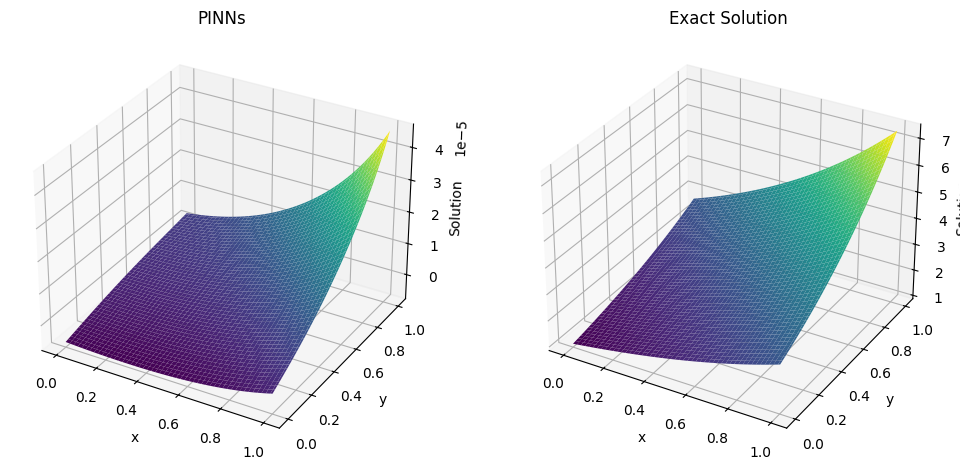

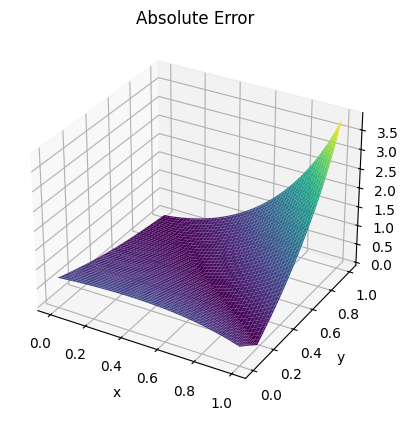

In [26]:
visualize_2d_time_sol(nn, solution, 0.001)

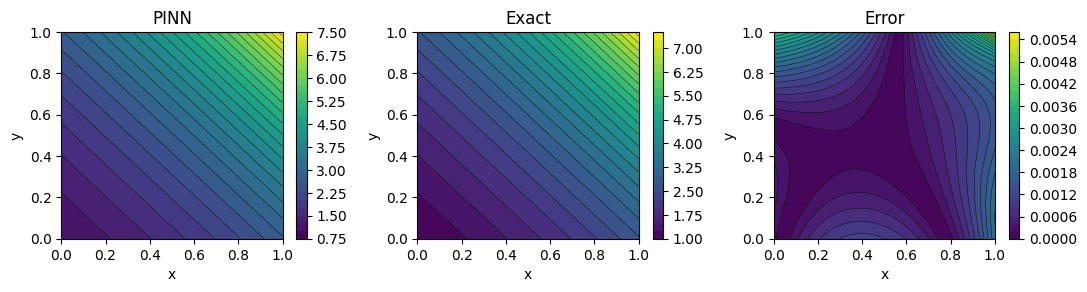

In [16]:
visualize_contour_sol(nn,solution,1.0)

In [22]:
import numpy as np
from scipy.integrate import nquad


def difference_func(x,y, t):
    xt = np.array([[x, y,t]])
    diff = (nn.predict(xt)[0, 0] - solution(xt)[0, 0])**2
    return diff

result, error = nquad(difference_func, [[0, 1], [0, 1], [0,1]], opts={'epsabs': 1e-3, 'epsrel': 1e-3})
print(result**0.5)

0.0003182278749374539


In [9]:
tf.print(5/(1+tf.exp(-nn.G)))

3.3958934958769644
